In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np

# Один нейрон: калибровка биохимического анализатора

Эта задача — мост между двумя твоими берегами. Первый — численные методы, которыми ты занимаешься с лета: функции ошибки, градиентный спуск, МНК. Второй — нейросети, к которым мы идём с апрельского классификатора цветов. Мост короче, чем кажется: **обучение нейросети — это калибровка**, только параметров больше. Здесь ты пройдёшь весь цикл на настоящей лабораторной задаче и увидишь, что «один нейрон» — не метафора, а рабочая формула из ежедневной практики клинической лаборатории.

## Блок 0. Что понадобится

- **Инструменты:** чистый Python + `math` + `matplotlib`. `numpy` понадобится только в необязательных заданиях 4.5* и 4.12* (линии уровня). Никаких библиотек ML.
- **Что уже умеем:** минимизировать функцию двух параметров (блок численных методов), градиентный спуск с шагом и критерием останова (октябрь), МНК по нормальным уравнениям (июль).
- **Новой математики здесь нет.** Новые только названия — и новый источник данных: измерения, а не задачник.
- **Формат работы прежний:** сначала бумага, потом Jupyter, потом сверка. Задания с пометкой «на бумагу» делаются без компьютера и без ИИ.
- **Прежде чем прислать:** `Restart Kernel and Run All` — ноутбук должен прогоняться целиком с нуля, с сохранённым выводом текущего кода.

## Блок 1. Откуда берётся задача

Ты сдаёшь кровь на глюкозу. В бланке анализа — число в ммоль/л. Но анализатор не умеет «чувствовать» концентрацию: он умеет измерять свет.

Цепочка такая:

1. Из пробирки берут плазму и смешивают с реагентом. В реагенте — фермент **глюкозооксидаза**: он окисляет глюкозу, и в реакции образуется окрашенное вещество. Чем больше глюкозы — тем сильнее окраска. Тот же фермент — на полоске домашнего глюкометра.
2. Смесь заливают в кювету — маленький прозрачный сосуд — и ставят в **фотометр**: прибор просвечивает кювету лучом света и измеряет, сколько света дошло до детектора.
3. Прибор выдаёт **оптическую плотность** $A$ — число, которое растёт с поглощением. Всё. Больше прибор ничего не знает.

И вот вопрос: в бланке — ммоль/л, прибор знает только $A$. **Откуда берётся перевод?** Ни из воздуха, ни из инструкции — из **калибровки**: перед работой через прибор прогоняют несколько растворов с точно известными концентрациями (калибраторов) и по этим точкам строят прямую. Вся лаборатория потом живёт на этой прямой: калибруют раз в смену, а пациентские пробы проходят через неё весь день.

В этой задаче ты — тот, кто строит эту прямую и **учит по ней нейрон переводить измерение в концентрацию**. Строишь дважды (на глаз и по-инженерному), проверяешь на контрольном материале и запускаешь инференс для пациентских проб.

**Почитать:**
- [Закон Бугера — Ламберта — Бера](https://ru.wikipedia.org/wiki/Закон_Бугера_—_Ламберта_—_Бера) — физика поглощения света раствором.
- [Глюкозооксидаза](https://ru.wikipedia.org/wiki/Глюкозооксидаза) — фермент из реагента и его роль в глюкометрах.

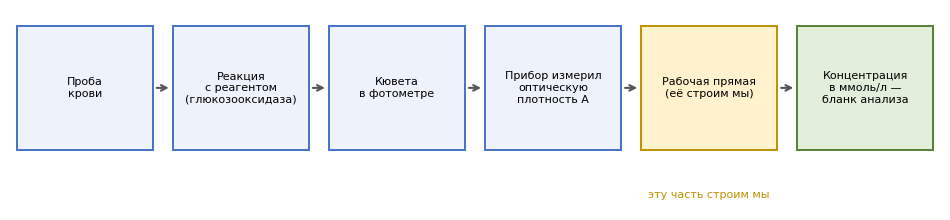

In [24]:
# Рисунок 1. Путь пробы: от крови до числа в бланке
fig, ax = plt.subplots(figsize=(12, 2.6))

steps = [
    ('Проба\nкрови', '#eef3fb', '#4472c4'),
    ('Реакция\nс реагентом\n(глюкозооксидаза)', '#eef3fb', '#4472c4'),
    ('Кювета\nв фотометре', '#eef3fb', '#4472c4'),
    ('Прибор измерил\nоптическую\nплотность A', '#eef3fb', '#4472c4'),
    ('Рабочая прямая\n(её строим мы)', '#fff2cc', '#bf9000'),
    ('Концентрация\nв ммоль/л —\nбланк анализа', '#e2efda', '#548235'),
]
for i, (text, fc, ec) in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 1.15, 0.30), 1.0, 0.62, facecolor=fc, edgecolor=ec, lw=1.4))
    ax.text(i * 1.15 + 0.5, 0.61, text, ha='center', va='center', fontsize=8)
    if i < len(steps) - 1:
        ax.annotate('', xy=(i * 1.15 + 1.14, 0.61), xytext=(i * 1.15 + 1.01, 0.61),
                    arrowprops=dict(arrowstyle='->', lw=1.5, color='#555555'))
ax.text(4 * 1.15 + 0.5, 0.06, 'эту часть строим мы', ha='center', fontsize=8, color='#bf9000')
ax.set_xlim(-0.05, 5 * 1.15 + 1.05)
ax.set_ylim(0, 1.0)
ax.axis('off')
plt.show()

## Блок 2. Как измеряют и что именно мы ищем

### 2.1. Свет через кювету

Фотометр посылает в кювету луч известной интенсивности $I_0$ и ловит на выходе то, что осталось: $I$. Поглощение — это то, что исчезло. Чтобы поглощение удобно складывалось (два слоя одного раствора — двукратное поглощение), берут не разность и не отношение, а **десятичный логарифм отношения**:

$$A = -\lg\frac{I}{I_0}$$

Интуиция: если раствор поглотил 90% света, то $I/I_0 = 0.1$ и $A = 1$. Поглотил 99% — $A = 2$. Каждый единичный шаг $A$ — падение прошедшего света в десять раз. Больше глюкозы → темнее раствор → меньше $I$ → больше $A$.

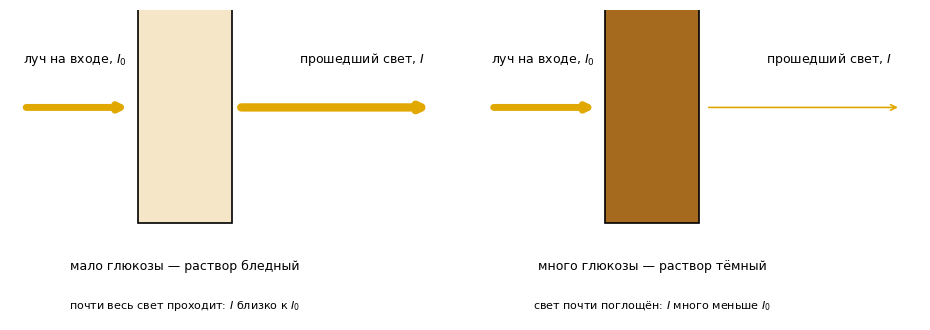

In [25]:
# Рисунок 2. Одна и та же кювета при разной концентрации
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
cases = [
    ('#f5e6c8', 6.0, 'мало глюкозы — раствор бледный', 'почти весь свет проходит: $I$ близко к $I_0$'),
    ('#a56a1e', 1.2, 'много глюкозы — раствор тёмный', 'свет почти поглощён: $I$ много меньше $I_0$'),
]
for ax, (color, w_out, title, sub) in zip(axes, cases):
    ax.add_patch(plt.Rectangle((0.75, 0.55), 0.7, 1.3, facecolor=color, edgecolor='black', lw=1.2))
    ax.annotate('', xy=(0.70, 1.2), xytext=(-0.10, 1.2),
                arrowprops=dict(arrowstyle='->', lw=5, color='#e0a800'))
    ax.annotate('', xy=(2.95, 1.2), xytext=(1.50, 1.2),
                arrowprops=dict(arrowstyle='->', lw=w_out, color='#e0a800'))
    ax.text(-0.10, 1.45, 'луч на входе, $I_0$', fontsize=9)
    ax.text(1.95, 1.45, 'прошедший свет, $I$', fontsize=9)
    ax.text(1.10, 0.28, title, ha='center', fontsize=9)
    ax.text(1.10, 0.06, sub, ha='center', fontsize=8)
    ax.set_xlim(-0.20, 3.10)
    ax.set_ylim(0, 1.75)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2.2. Закон Бера — и почему прямая не из нуля

По закону Бугера — Ламберта — Бера поглощение раствора **пропорционально концентрации** окрашенного вещества:

$$A = k\,c + A_0$$

где $c$ — концентрация, $k$ — чувствительность методики (сколько плотности даёт каждый ммоль/л). Идеальная пропорциональность проходила бы через ноль, но есть неудобная правда: даже там, где глюкозы **ноль**, раствор всё равно чуть-чуть поглощает — красит сам реагент, слегка мутнит проба, неидеальна кювета. Это называется **холостая проба** (blank), и из-за неё у прямой появляется свободный член $A_0$: что прибор покажет при нулевой концентрации.

Такую картину физика пишет «слева направо»: **дана концентрация — какой будет плотность**. Это модель прибора.

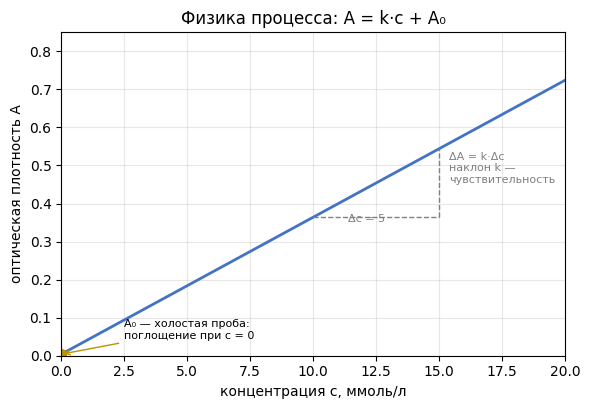

In [26]:
# Рисунок 3. Физика процесса: плотность как функция концентрации
k, A0 = 0.036, 0.004
c = [0.5 * i for i in range(0, 41)]      # от 0 до 20
A = [k * x + A0 for x in c]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(c, A, color='#4472c4', lw=2)
ax.plot([0.0], [A0], 'o', color='#bf9000', ms=7)

ax.annotate('A₀ — холостая проба:\nпоглощение при c = 0', xy=(0, A0), xytext=(2.5, 0.045),
            fontsize=8, arrowprops=dict(arrowstyle='->', color='#bf9000'))
ax.plot([10, 15], [k * 10 + A0, k * 10 + A0], '--', color='gray', lw=1)
ax.plot([15, 15], [k * 10 + A0, k * 15 + A0], '--', color='gray', lw=1)
ax.text(11.4, k * 10 + A0 - 0.012, 'Δc = 5', fontsize=8, color='gray')
ax.text(15.4, k * 12.5 + A0, 'ΔA = k·Δc\nнаклон k —\nчувствительность', fontsize=8, color='gray')

ax.set_xlabel('концентрация c, ммоль/л')
ax.set_ylabel('оптическая плотность A')
ax.set_title('Физика процесса: A = k·c + A₀')
ax.grid(alpha=0.3)
ax.set_xlim(0, 20)
ax.set_ylim(0, 0.85)
plt.show()


### 2.3. Читаем ту же прямую в рабочую сторону — получаем нейрон

В работе прибор делает ровно наоборот: он **измерил** $A$ — и ему (и нам) нужно узнать $c$. Ту же самую прямую можно прочитать справа налево:

$$\hat{c} = w\,A + b$$

- **вход** — измеренная оптическая плотность $A$;
- **выход** — предсказанная концентрация $\hat{c}$ (шляпка над буквой — стандартное обозначение предсказания модели);
- $w$ — вес, $b$ — смещение. Они связаны с физическими параметрами: примерно $w \approx 1/k$ и $b \approx -A_0/k$ (насколько точно — задание 4.12*).

Именно в таком виде рисуют **нейрон**: вход умножается на вес, добавляется смещение, получается выход. Мы обучаем ровно то, чем потом пользуемся: нейрон, которому на вход дали измерение, а на выходе — ответ в ммоль/л.

Две оговорки.

Первая: свободный член $b$ сам по себе ничего не значит (у нас он получится отрицательным — «концентрация меньше нуля», странно звучит, но это просто точка пересечения оси). Зато осмысленна точка, где выход нейрона **обнуляется**: $A = -b/w$. Вспомни холостую пробу из 2.2 — и скажи, чему эта точка равна и как она связана с $A_0$. Проверишь числом в 4.9.

Вторая: схема ниже — ровно наш случай: один вход, один вес, одно смещение, ничего лишнего. Многовходовый вариант ты уже встречала в апреле — классификатор цветов брал три входа (R, G, B) и три веса; картинка та же, только линий больше.

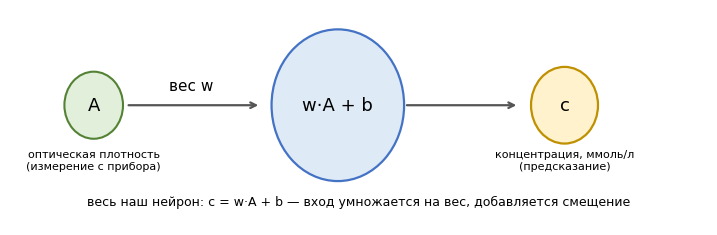

In [27]:
# Рисунок 4. Наш нейрон: один вход, один вес, одно смещение
fig, ax = plt.subplots(figsize=(9.0, 2.8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 2.7)
ax.axis('off')

ax.add_patch(Circle((1.2, 1.5), 0.42, facecolor='#e2efda', edgecolor='#548235', lw=1.5))
ax.text(1.2, 1.5, 'A', ha='center', va='center', fontsize=13)
ax.text(1.2, 0.70, 'оптическая плотность\n(измерение с прибора)', ha='center', fontsize=8)

ax.annotate('', xy=(3.60, 1.5), xytext=(1.66, 1.5),
            arrowprops=dict(arrowstyle='->', lw=1.6, color='#555555'))
ax.text(2.60, 1.68, 'вес w', fontsize=11, ha='center')

ax.add_patch(Circle((4.70, 1.5), 0.95, facecolor='#deebf7', edgecolor='#4472c4', lw=1.6))
ax.text(4.70, 1.5, 'w·A + b', ha='center', va='center', fontsize=13)

ax.annotate('', xy=(7.30, 1.5), xytext=(5.65, 1.5),
            arrowprops=dict(arrowstyle='->', lw=1.6, color='#555555'))

ax.add_patch(Circle((7.95, 1.5), 0.48, facecolor='#fff2cc', edgecolor='#bf9000', lw=1.6))
ax.text(7.95, 1.5, 'c', ha='center', va='center', fontsize=13)
ax.text(7.95, 0.70, 'концентрация, ммоль/л\n(предсказание)', ha='center', fontsize=8)

ax.text(5.0, 0.25, 'весь наш нейрон: c = w·A + b — вход умножается на вес, добавляется смещение',
        ha='center', fontsize=9)
plt.show()


### 2.4. Что значит «нейрон обучен правильно»

Нейрон задан парой чисел $(w, b)$. Какая пара лучше? Знакомый ответ: та, у которой меньше сумма квадратов отклонений предсказаний от истинных концентраций:

$$S(w, b) = \sum_{i=1}^{5}\left(c_i - (w A_i + b)\right)^2$$

Здесь $c_i$ — известные концентрации калибраторов, $A_i$ — измеренные плотности. Обрати внимание на единицу: $S$ складывает ошибки **в ммоль/л** — мы минимизируем именно ту ошибку, которая попадёт в пациентский бланк.

Это функция двух параметров — ровно тот класс задач, который ты решала весь сентябрь. Минимум можно взять аналитически (задание 4.6), можно градиентным спуском (4.5). Сходимость двух способов к одному числу — главная проверка всей задачи.

**Вопросы на понимание** — ответь письменно в ячейках ниже, прежде чем идти дальше:

1. Раствор А вдвое концентрированнее раствора Б, оба в рабочем диапазоне. Что можно сказать об их оптических плотностях?
2. Физическая прямая из 2.2 выходит из точки $A_0 = 0.012$, а не из нуля. Что именно «добавляет» эти $0.012$?
3. Почему при реальных измерениях $S$ в минимуме — не ноль, и почему это нормально?

**Ответ 1.** Оптическая плотность раствора А будет вдвое больше оптической плотности раствора Б так как между Оптической плотностью и концентрацией раствора имеется линейная зависимость. 

**Ответ 2.** Даже при отсутствии глюкозы в растворе происходит поглощение света. Это является следствием налиичия в растворе красителя, возможной неидеальности кюветы и мутностью самого раствора. 

**Ответ 3.** Ввиду невозможности избавления от всех минимальных погрешностей. 

## Блок 3. Обучающая выборка

Калибровочный набор для глюкозы (метод GOD-PAP): пять растворов с точно известными концентрациями. Каждый прогнан через прибор; в таблице — измеренные оптические плотности.

| Раствор | $c$, ммоль/л | $A$ |
|---|---|---|
| Калибратор 1 | 2.5 | 0.095 |
| Калибратор 2 | 5.0 | 0.183 |
| Калибратор 3 | 10.0 | 0.364 |
| Калибратор 4 | 15.0 | 0.546 |
| Калибратор 5 | 20.0 | 0.723 |

Кроме них в наборе есть ещё три материала — и **в обучении они не участвуют**:

| Материал | Что известно заранее | Измерено |
|---|---|---|
| Контрольный материал | приписанное значение $c = 6.25$ ммоль/л | $A = 0.235$ |
| Пациентская проба 1 | ничего | $A = 0.415$ |
| Пациентская проба 2 | ничего | $A = 0.950$ |

Роль каждого: калибраторы — **обучающая выборка**; контрольный материал — **проверка** обученного нейрона на материале с известным ответом (в лаборатории шаг обязательный: калибровка без пройденного контроля недействительна); пациентские пробы — **инференс**, то, ради чего всё строилось.

> Числа здесь модельные: они воспроизводят порядок величин типового калибровочного набора для глюкозы. Точные значения конкретного набора пишутся в его паспорте — в реальной лаборатории числа берутся оттуда, и подменять их «правдоподобными» нельзя.

**Задание 0 (на бумагу).** Прежде чем открывать код: нанеси пять точек на лист так, как их будет читать нейрон, — по горизонтали $A$, по вертикали $c$. Приложи линейку и прикинь:
- $w$ — сколько ммоль/л приходится на единицу оптической плотности;
- $b$ — где твоя прямая пересечёт вертикальную ось (чуть ниже нуля — и это ожидаемо, вспомни 2.3).

Запиши оба числа — они станут стартовой гипотезой в 4.2. Именно так калибровку строили вручную десятилетиями: сначала линейка, потом формулы.
Полученные числа: w_eye = 28  b_eye = -0.1 

## Блок 4. Программируем

Правила прежние: каждое задание — условие → код → вывод с проверкой. Пустые ячейки — твои. Присланный ноутбук должен быть прогнан целиком (`Restart Kernel and Run All`), с выводом, а не текстом программы.

На схеме буквы без шляпок: A, w, b, c; в формулах предсказание помечается шляпкой: $\hat{c}$. Смещение везде — просто $b$.

### 4.1. Выборка на графике

Запиши калибраторы двумя списками (`A_cal`, `c_cal`) и построй scatter-график в осях нейрона: по горизонтали $A$, по вертикали $c$. Подписи осей с единицами, сетка, разумные пределы.

*Что должно получиться:* пять точек, почти лежащих на прямой, — глазом видны и наклон, и точка пересечения оси.

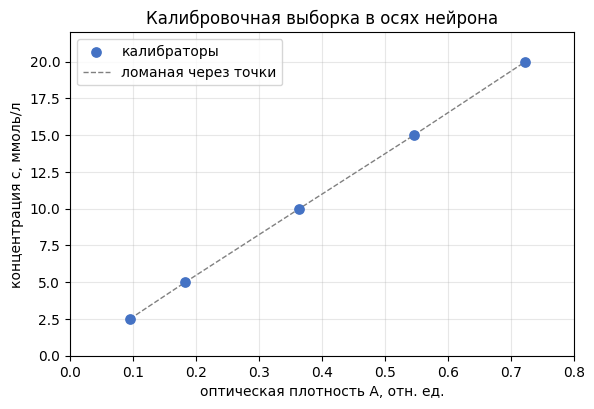

In [28]:
# 4.1 — выборка в осях нейрона (A, c): график точек

A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(A_cal, c_cal, s=45, color='#4472c4', zorder=3, label='калибраторы')
ax.plot(A_cal, c_cal, color='gray', ls='--', lw=1, zorder=2, label='ломаная через точки')
ax.set_xlabel('оптическая плотность A, отн. ед.')
ax.set_ylabel('концентрация c, ммоль/л')
ax.set_title('Калибровочная выборка в осях нейрона')
ax.grid(alpha=0.3)
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 22)
ax.legend()
plt.show()

### 4.2. Гипотеза на глаз

Запиши прикидку из задания 0 как `w_eye`, `b_eye`. Нарисуй прямую $\hat{c} = w_{\text{eye}} A + b_{\text{eye}}$ поверх точек (диапазон $A$ — от 0 до 0.8). В заголовок графика вынеси значения обоих параметров.

*Проверка глазами:* прямая проходит по точкам? Запомни, как она выглядит, — сравним с точной в 4.7.

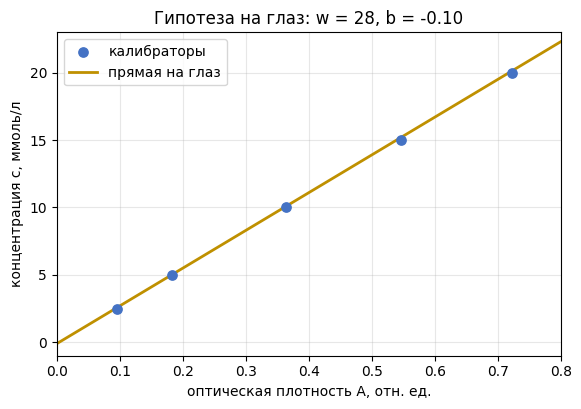

In [29]:
# 4.2 — прикидка на глаз: w_eye, b_eye и прямая поверх точек
w_eye = 28     # ммоль/л на единицу A
b_eye = -0.1    # сдвиг прямой по вертикали   

A_line = np.linspace(0, 0.8, 200)
c_line = w_eye * A_line + b_eye

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(A_cal, c_cal, s=45, color='#4472c4', zorder=3, label='калибраторы')
ax.plot(A_line, c_line, color='#bf9000', lw=2, zorder=2, label='прямая на глаз')
ax.set_xlabel('оптическая плотность A, отн. ед.')
ax.set_ylabel('концентрация c, ммоль/л')
ax.set_title(f'Гипотеза на глаз: w = {w_eye:.0f}, b = {b_eye:+.2f}')
ax.grid(alpha=0.3)
ax.set_xlim(0, 0.8)
ax.set_ylim(-1, 23)
ax.legend()
plt.show()

### 4.3. Цена ошибки

Напиши функцию `S(w, b)` — сумму квадратов отклонений предсказанных концентраций от истинных. Посчитай и выведи:
- $S(w_{\text{eye}}, b_{\text{eye}})$ — сколько стоит гипотеза «на глаз»;
- $S(10, 0)$ — заведомо плохая пара.

Плохая пара обязана быть дороже на порядки. Если это не так — в `S` ошибка, найди её до следующего задания.

In [30]:
# 4.3 — функция S(w, b) и её значения для двух пар параметров

A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]

def S(w, b):
    total_error = 0
    for i in range(len(A_cal)):
        c_predicted = w * A_cal[i] + b     # предсказание нейрона
        error = c_cal[i] - c_predicted     # разница с истиной
        total_error += error ** 2          # квадрат ошибки в общую копилку
    return total_error

# полученные "на глаз" параметры
w_eye = 28.0   
b_eye = -0.1   

s_eye = S(w_eye, b_eye)
s_bad = S(10, 0)

print(f"Цена гипотезы 'на глаз': S({w_eye}, {b_eye}) = {s_eye:.4f}")
print(f"Цена плохой пары: S(10, 0) = {s_bad:.4f}")
print(f"Плохая пара дороже в {s_bad / s_eye:.0f} раз")

Цена гипотезы 'на глаз': S(28.0, -0.1) = 0.0687
Цена плохой пары: S(10, 0) = 306.9855
Плохая пара дороже в 4467 раз


### 4.4. Производные — на бумагу

Выпиши $\dfrac{\partial S}{\partial w}$ и $\dfrac{\partial S}{\partial b}$ для нашей $S$: раскрой квадрат, продифференцируй по каждому параметру. Ты делала это в июле для пяти точек прямой — задача та же, буквы другие: тогда точки назывались $(x, y)$ и параметры были при $x$, здесь точки $(A, c)$ и параметры при $A$.

Проверка будет немедленной: если производные верные, спуск в 4.5 сойдётся ровно к ответу формулы из 4.6.

**Ответ 4.4 (формулы $\partial S/\partial w$ и $\partial S/\partial b$).**

Раскрываем квадрат: $S_i$ = $c_i^2 + w^2A_i^2 + b^2 - 2c_iwA_i - 2c_ib +2wA_ib$ 

$\partial S/\partial w$ = $2wA_i^2 - 2c_iA_i + 2A_ib = 2A_i(wA_i - c_i +b)$

$\partial S/\partial b$ = $2b - 2c_i +2wA_i = 2(b-c_i + wA_i)$

$$\frac{\partial S}{\partial w} = -2\sum_{i=1}^{5} A_i\left(c_i - wA_i - b\right)$$

$$\frac{\partial S}{\partial b} = -2\sum_{i=1}^{5}\left(c_i - wA_i - b\right)$$

### 4.5. Градиентный спуск

Реализуй спуск по двум параметрам сразу:

1. посчитай обе производные при текущих $(w, b)$;
2. обнови **обе** координаты: $w \leftarrow w - \eta\,\dfrac{\partial S}{\partial w}$, $b \leftarrow b - \eta\,\dfrac{\partial S}{\partial b}$ (сначала обе производные, потом оба обновления — иначе получится покоординатный шаг);
3. повтори.

Старт: $w = 0$, $b = 0$ (потом попробуй и свою прикидку — сравни число итераций). Шаг: начни с $\eta = 0.1$; помнишь из сентября, у шага есть граница устойчивости — здесь она своя. Ленивое упражнение со звёздочкой: найди $\eta$, при котором спуск расходится.

Финал: напечатай найденные $w$, $b$; построй **кривую обучения** — график $S$ по итерациям (вертикальную ось удобно сделать логарифмической). Сошёлся? За сколько итераций $S$ упала хотя бы в 100 раз от старта?

Градиент в старте (0, 0): dS/dw = -54.8850, dS/db = -105.0000
Спуск из (0, 0):     w = 27.788367, b = -0.120714, S = 0.005217
S упала в 100 раз на итерации 32
Спуск из прикидки:   w = 27.788367, b = -0.120714, S = 0.005217
с прикидки S стартует в 0.0687 и ниже 0.01 уходит за 6 итераций против 111 из нуля
Граница устойчивости: eta* = 2/lambda_max = 0.1734
  eta = 0.10: S после 50 итераций = 1.384e+00
  eta = 0.17: S после 50 итераций = 1.056e+01
  eta = 0.18: S после 50 итераций = 8.836e+05
  eta = 0.20: S после 50 итераций = 2.414e+14


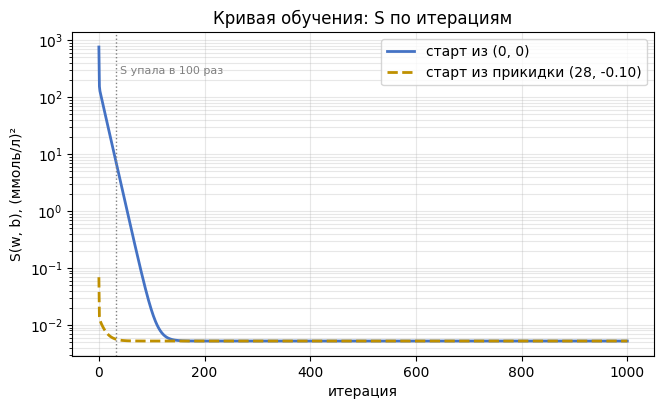

In [31]:
# 4.5 — градиентный спуск по (w, b) и кривая обучения

A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]

def S(w, b):
    return sum((c - (w * A + b)) ** 2 for A, c in zip(A_cal, c_cal))

# производные: 2·Σ A_i·(wA_i + b - c_i) и 2·Σ (wA_i + b - c_i)
# (это те же формулы из 4.4, только знак вынесен так, чтобы был плюс)
def dS_dw(w, b):
    return 2 * sum(A * (w * A + b - c) for A, c in zip(A_cal, c_cal))

def dS_db(w, b):
    return 2 * sum(w * A + b - c for A, c in zip(A_cal, c_cal))

def descent(w0, b0, eta=0.1, iters=1000):
    w, b = w0, b0
    history = [S(w, b)]
    for _ in range(iters):
        dw = dS_dw(w, b)          # обе производные считаем до обновления
        db = dS_db(w, b)
        w = w - eta * dw          # и только потом обновляем обе координаты
        b = b - eta * db
        history.append(S(w, b))
    return w, b, history

print(f"Градиент в старте (0, 0): dS/dw = {dS_dw(0, 0):.4f}, dS/db = {dS_db(0, 0):.4f}")

w_gd, b_gd, hist = descent(0.0, 0.0)
n100 = next(i for i, s in enumerate(hist) if s <= hist[0] / 100)
print(f"Спуск из (0, 0):     w = {w_gd:.6f}, b = {b_gd:.6f}, S = {hist[-1]:.6f}")
print(f"S упала в 100 раз на итерации {n100}")

w_e, b_e, hist_e = descent(w_eye, b_eye)
print(f"Спуск из прикидки:   w = {w_e:.6f}, b = {b_e:.6f}, S = {hist_e[-1]:.6f}")
print(f"с прикидки S стартует в {hist_e[0]:.4f} и ниже 0.01 уходит за "
      f"{next(i for i, s in enumerate(hist_e) if s < 0.01)} итераций против "
      f"{next(i for i, s in enumerate(hist) if s < 0.01)} из нуля")

# граница устойчивости: шаг обязан быть меньше 2/λmax матрицы Гессе
from math import sqrt
a2 = sum(A ** 2 for A in A_cal)
a1 = sum(A_cal)
n = len(A_cal)
lam_max = (a2 + n) + sqrt((a2 - n) ** 2 + 4 * a1 ** 2)
print(f"Граница устойчивости: eta* = 2/lambda_max = {2 / lam_max:.4f}")
for eta in (0.1, 0.17, 0.18, 0.20):
    _, _, h = descent(0.0, 0.0, eta=eta, iters=50)
    print(f"  eta = {eta:.2f}: S после 50 итераций = {h[-1]:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(hist, color='#4472c4', lw=2, label='старт из (0, 0)')
ax.semilogy(hist_e, color='#bf9000', lw=2, ls='--',
            label=f'старт из прикидки ({w_eye:.0f}, {b_eye:+.2f})')
ax.axvline(n100, color='gray', ls=':', lw=1)
ax.text(n100 + 8, hist[0] / 3, 'S упала в 100 раз', fontsize=8, color='gray')
ax.set_xlabel('итерация')
ax.set_ylabel('S(w, b), (ммоль/л)²')
ax.set_title('Кривая обучения: S по итерациям')
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.show()


**Вывод:** градиентный спуск сходится из любой стартовой точки (хоть из нуля, хоть из прикидки) он приходит к одним и тем же значениям w = 27.79 и b = -0.12, где функция потерь падает почти до нуля. Если стартовать из прикидки "на глаз", спуск сходится в 18 раз быстрее (за 6 итераций вместо 111). При этом шаг обучения η не должен превышать 0.17: при больших значениях спуск начинает расходиться

### 4.5*. Линии уровня (необязательно, но красиво)

Построй линии уровня $S(w, b)$ вокруг найденного минимума (`contour` из `matplotlib`; `numpy` здесь разрешён) и нанеси на них траекторию спуска.

Посмотри на форму чаши: здесь она почти круглая — плотности у всех калибраторов одного масштаба (от 0.09 до 0.72), поэтому шаги по обоим параметрам одинаково удобны. Вытянутый овраг ты видела в сентябре не раз — где он здесь и почему вернётся только в 4.12*, станет понятно там.

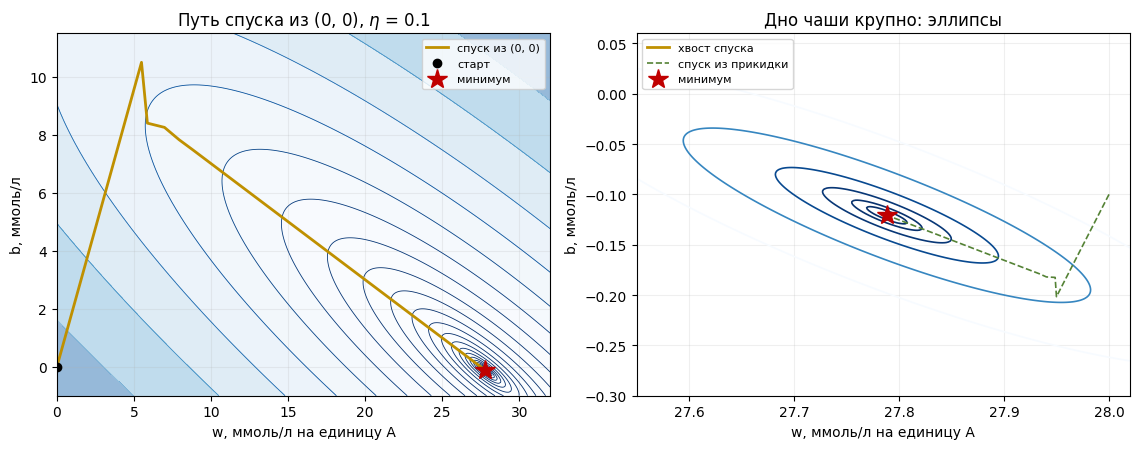

Минимум: w = 27.788350, b = -0.120707, S_min = 0.005217
Отношение полуосей эллипса sqrt(lambda_max/lambda_min) = 5.00


In [32]:
# 4.5* — линии уровня S(w, b) и траектория спуска

def trajectory(w0, b0, eta=0.1, iters=300):
    pts = [(w0, b0)]
    w, b = w0, b0
    for _ in range(iters):
        dw, db = dS_dw(w, b), dS_db(w, b)      # как в 4.5: обе до обновления
        w, b = w - eta * dw, b - eta * db
        pts.append((w, b))
    return np.array(pts)

def S_grid(W, B):
    A = np.array(A_cal)
    C = np.array(c_cal)
    return ((C - (W[..., None] * A + B[..., None])) ** 2).sum(axis=-1)

path = trajectory(0.0, 0.0)
path_eye = trajectory(w_eye, b_eye)
w_min, b_min = path[-1]
S_min = S(w_min, b_min)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# слева — вся картина: старт в (0, 0) далеко от дна
W, B = np.meshgrid(np.linspace(0, 32, 300), np.linspace(-1.0, 11.5, 300))
Z = S_grid(W, B)
lev = np.logspace(-3, np.log10(1000), 28)
ax1.contourf(W, B, Z, levels=lev, cmap='Blues', alpha=0.45)
ax1.contour(W, B, Z, levels=lev, cmap='Blues_r', linewidths=0.6)
ax1.plot(path[:, 0], path[:, 1], color='#bf9000', lw=2, label='спуск из (0, 0)')
ax1.plot(path[0, 0], path[0, 1], 'o', color='black', ms=6, label='старт')
ax1.plot(w_min, b_min, '*', color='#c00000', ms=15, label='минимум')
ax1.set_xlabel('w, ммоль/л на единицу A')
ax1.set_ylabel('b, ммоль/л')
ax1.set_title('Путь спуска из (0, 0), $\\eta$ = 0.1')
ax1.set_xlim(0, 32)
ax1.set_ylim(-1, 11.5)
ax1.grid(alpha=0.2)
ax1.legend(fontsize=8)

# справа — крупно дно чаши: видно, что линии уровня — эллипсы
Wz, Bz = np.meshgrid(np.linspace(27.55, 28.02, 240), np.linspace(-0.30, 0.06, 240))
levels = S_min + np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
ax2.contour(Wz, Bz, S_grid(Wz, Bz), levels=levels, cmap='Blues_r', linewidths=1.2)
ax2.plot(path[-60:, 0], path[-60:, 1], color='#bf9000', lw=2, label='хвост спуска')
ax2.plot(path_eye[:, 0], path_eye[:, 1], color='#548235', lw=1.2, ls='--',
         label='спуск из прикидки')
ax2.plot(w_min, b_min, '*', color='#c00000', ms=15, label='минимум')
ax2.set_xlabel('w, ммоль/л на единицу A')
ax2.set_ylabel('b, ммоль/л')
ax2.set_title('Дно чаши крупно: эллипсы')
ax2.grid(alpha=0.2)
ax2.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.show()

print(f"Минимум: w = {w_min:.6f}, b = {b_min:.6f}, S_min = {S_min:.6f}")
print(f"Отношение полуосей эллипса sqrt(lambda_max/lambda_min) = "
      f"{sqrt(((a2 + n) + sqrt((a2 - n) ** 2 + 4 * a1 ** 2)) / ((a2 + n) - sqrt((a2 - n) ** 2 + 4 * a1 ** 2))):.2f}")


### 4.6. МНК: тот же ответ без итераций

Минимум квадратичной функции берётся аналитически: приравняй обе частные производные к нулю — получишь нормальные уравнения (ты выводила их в июле):

$$w \sum A_i^2 + b \sum A_i = \sum A_i c_i$$

$$w \sum A_i + n\,b = \sum c_i$$

Посчитай суммы по калибраторам, реши систему 2×2 (Крамер с определителем — ты его уже писала в той же июльской задаче) и напечатай `w_mnk`, `b_mnk`.

In [33]:
# 4.6 — нормальные уравнения: w_mnk, b_mnk по формуле
A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]
n = len(c_cal)

sum_A = sum(A_cal)
sum_A2 = sum(a**2 for a in A_cal)
sum_c = sum(c_cal)
sum_Ac = sum(A_cal[i] * c_cal[i] for i in range(n))
print(f"Значения sum_A = {sum_A} | sum_A2 = {sum_A2} | sum_c = {sum_c} | sum_Ac = {sum_Ac}")

# W * 0.995855 + B * 1.911 = 27.4425
#W * 1.911 + B * 5 = 52.5
D  = n * sum_A2 - sum_A * sum_A
Dw = n * sum_Ac - sum_A * sum_c
Db = sum_A2 * sum_c - sum_A * sum_Ac

#Находим w и b
w_mnk = Dw / D
b_mnk = Db / D

print(f"Точные значения по МНК:")
print(f"w_mnk = {w_mnk:.6f}")
print(f"b_mnk = {b_mnk:.6f}")


Значения sum_A = 1.911 | sum_A2 = 0.995855 | sum_c = 52.5 | sum_Ac = 27.4425
Точные значения по МНК:
w_mnk = 27.788367
b_mnk = -0.120714


### 4.7. Два пути к одному числу

Напечатай рядом $(w, b)$ из спуска и из формулы, посчитай модули разностей. Два независимых пути обязаны сойтись — это твоя стандартная самопроверка. Если расходятся после четвёртого знака — сначала проверь производные, потом шаг и число итераций спуска.

Здесь же сравни с прикидкой на глаз из 4.2: насколько «глаз» ошибся в $w$ и $b$? Выведи и это.

In [34]:
# 4.7 — сверка: спуск против МНК, и обе против глаза
difference_w = abs(w_mnk - w_gd)
difference_b = abs(b_mnk - b_gd)
print(f"Разница между значениями параметров найденных методом градиентного спуска и МНК составила для w: {difference_w:.7f}, для b:{difference_b:.7f}")

error_eye_w = abs(w_mnk - w_eye)
error_eye_b = abs(b_mnk - b_eye)
print(f"Разница между значениями параметров найденных методом МНК и 'на глаз' составила для w: {error_eye_w:.6f}, для b:{error_eye_b:.6f}")

Разница между значениями параметров найденных методом градиентного спуска и МНК составила для w: 0.0000000, для b:0.0000000
Разница между значениями параметров найденных методом МНК и 'на глаз' составила для w: 0.211633, для b:0.020714


### 4.8. Остатки

Для каждого калибратора посчитай остаток: $r_i = c_i - (w A_i + b)$ — на сколько ммоль/л ошибся бы анализ на этом растворе. Выведи все пять.

И главное — вывод словами: знаки разбросаны вперемешку (случайный шум прибора — нейрон честно описывает данные) или выстроились в закономерность (например, первые в плюс, последние в минус — модель что-то упускает)? Этот вопрос — центральный для следующего этапа, не пропускай его.

In [35]:
# 4.8 — остатки по каждому калибратору, ммоль/л
# Данные и параметры из предыдущих шагов (подставь свои, если они чуть отличаются)
print("Остатки (ошибки) по каждому калибратору, ммоль/л:")
for i in range(len(A_cal)):
    # Предсказание нейрона
    c_pred = w_mnk * A_cal[i] + b_mnk
    # истина минус предсказание
    r_i = c_cal[i] - c_pred 

    print(f"Калибратор {i+1} (c = {c_cal[i]}): {r_i:.4f}")

Остатки (ошибки) по каждому калибратору, ммоль/л:
Калибратор 1 (c = 2.5): -0.0192
Калибратор 2 (c = 5.0): 0.0354
Калибратор 3 (c = 10.0): 0.0057
Калибратор 4 (c = 15.0): -0.0517
Калибратор 5 (c = 20.0): 0.0297


In [36]:
print(f"Относительные ошибки по каждому калибратору:")
for i in range(len(A_cal)):
    c_pred = w_mnk * A_cal[i] + b_mnk
    # истина минус предсказание
    r_i = c_cal[i] - c_pred 
    rel_error = (abs(r_i) / c_cal[i]) * 100
    print(f"Калибратор {i+1} (c = {c_cal[i]}): {rel_error:.4f}%")

Относительные ошибки по каждому калибратору:
Калибратор 1 (c = 2.5): 0.7672%
Калибратор 2 (c = 5.0): 0.7089%
Калибратор 3 (c = 10.0): 0.0575%
Калибратор 4 (c = 15.0): 0.3449%
Калибратор 5 (c = 20.0): 0.1486%


**Ответ 4.8 (остатки — шум или система, и почему).** Знаки остатков разбросаны вперемешку, без монотонной закономерности - значит, это случайный шум измерительного прибора, а не систематическая ошибка модели. Максимальная ошибка наблюдалась у калибратора 4 (c = 15.0) и  составила 0.43%

### 4.9. Контрольный материал

Лаборатория не выпускает результаты после калибровки, пока та не подтверждена контролем: материал с **приписанным** значением $c = 6.25$ ммоль/л измерен на приборе и дал $A = 0.235$.

Прогони это измерение через свой нейрон — прямой проход: $\hat{c} = w A + b$. Сравни предсказание с приписанным значением: допуск обычно $\pm 10\%$.

И второй вопрос туда же: при какой оптической плотности твой нейрон обнуляется ($A = -b/w$)? Что это за точка физически — вспомни холостую пробу из 2.2. Совпало ли твоё ожидание с числом?

Уложилась ли калибровка? Можно ли работать с пациентами? Запиши вывод — это решение, а не комментарий.

In [37]:
# 4.9 — контрольный материал: прямой проход, допуск, точка нуля
c_lab = 6.25
A_lab = 0.235

c_pred = w_mnk * A_lab + b_mnk
print(f"Концентрация: {c_pred:.4f} ммоль/л")

# 2. Проверка допуска +- 10%
tolerance = 0.10
min_value = c_lab * (1 - tolerance)
max_value = c_lab * (1 + tolerance)

if min_value <= c_pred <= max_value: 
    print(f"Значение В диапазоне допуска [{min_value:.4f}, {max_value:.4f}]")
else:
    print(f"Значение НЕ в диапазоне допуска [{min_value:.4f}, {max_value:.4f}]")

Концентрация: 6.4096 ммоль/л
Значение В диапазоне допуска [5.6250, 6.8750]


In [38]:
a_zero = -b_mnk / w_mnk
A0 = 0.004  

print(f"Точка при которой нейрон обнуляет A = {a_zero:.4f}")
print(f"Холостая проба из 2.2: A0 = {A0:.4f}")
print(f"Совпадение: {abs(a_zero - A0):.4f}")

Точка при которой нейрон обнуляет A = 0.0043
Холостая проба из 2.2: A0 = 0.0040
Совпадение: 0.0003


**Вывод:** Калибровка уложилась, полученное значение находится в диапазоне допуска (10%), следовательно подходит для работы с пациентами. Физически это холостая проба, на значение А0 влияет собственная оптическая плотность реагента и кюветы при нулевой концентрации глюкозы.

### 4.10. Инференс: пациентские пробы

**Проба 1:** $A = 0.415$. Прямой проход нейрона — какая концентрация? (Для справки: норма глюкозы плазмы натощак — примерно до 6.1 ммоль/л. Что бы ты написала в заключении?)

**Проба 2:** $A = 0.950$. Сначала посмотри на верхний калибратор — и заметь, что нейрон **молча выдаст число**: посчитай какое. Формула безотказна и ответит всегда, даже там, где её знаниям верить нельзя. В лаборатории такую пробу не экстраполируют, а разводят (например, вдвое), перемеряют и только потом умножают результат обратно. Запрет живёт не в формуле — в регламенте, и держит его человек.

Почему экстраполяции нельзя верить — сформулируй своими словами. Подсказка была в Блоке 1: в статье про закон Бера сказано, что при больших концентрациях наблюдаются отклонения от пропорциональности. За пределами калибраторов наша прямая — уже не факт, а надежда.

In [39]:
# 4.10 — инференс: две пациентские пробы
A1 = 0.415
pred1 = w_mnk * A1 + b_mnk
print(f"Конц. глюкозы: {pred1:.1f} ммоль/л")
if 3.9 <= pred1 <= 6.1:
    diagnosis = "Глюкоза в норме"
elif pred1 < 3.9:
    diagnosis = "Глюкоза ниже нормы"
else:
    diagnosis = "Глюкоза выше нормы"

print(diagnosis)


Конц. глюкозы: 11.4 ммоль/л
Глюкоза выше нормы


In [40]:
A2 = 0.950
A_max_cal = max(A_cal)  # Верхняя граница калибровки (0.723)
pred2 = w_mnk * A2 + b_mnk
print(f"Конц. глюкозы: {pred2:.1f} ммоль/л")
print(f"Измеренная плотность A = {A2} > {A_max_cal} (верхний калибратор).")

Конц. глюкозы: 26.3 ммоль/л
Измеренная плотность A = 0.95 > 0.723 (верхний калибратор).


**Ответ 4.10 (почему пробу 2 разводят, а не верят числу из формулы).**

Максимальный калибратор был при оптической плотности А = 0,723, а проба 2 считается при A = 0,950. Соответственно, мы можем гарантировать линейную зависимость С от A до значения А = 0,723, далее только предположение. В реальности при высоких концентрациях закон Бера часто нарушается, и реальный график перестает быть прямым и «загибается».
Нейрон же продолжит прямую линию в никуда. Поэтому по лабораторному регламенту такую пробу разводят, перемеряют, чтобы оптическая плотность попала внутрь проверенного диапазона, а затем умножают полученный результат на коэффициент разведения.  

### 4.11*. SGD — как учатся настоящие сети (необязательно)

В 4.5 ты обновляла параметры один раз за проход по **всем** калибраторам. А теперь обновляй после **каждого** раствора, проходя по ним по кругу много эпох (внутри эпохи порядок не меняй). Это стохастический градиентный спуск, SGD. Когда точек миллионы, полный градиент пересчитывать дорого — и все реальные сети учатся именно так.

Сравни на одном графике кривые обучения: полный градиент против SGD (усредняй $S$ внутри эпохи, иначе кривая будет дрожать). Что изменилось: скорость, конечная точность, характер кривой?

полный градиент: w = 27.788350, b = -0.120707, S = 0.005217
SGD:             w = 27.797320, b = -0.123156, S = 0.005385
S_min по МНК:    w = 27.788367, b = -0.120714, S_min = 0.005217
эпох до S < 0.01: полный градиент — 111, SGD — 102
промах SGD от МНК: |dw| = 0.0090, |db| = 0.0024
промах полного градиента от МНК: |dw| = 0.0000, |db| = 0.0000


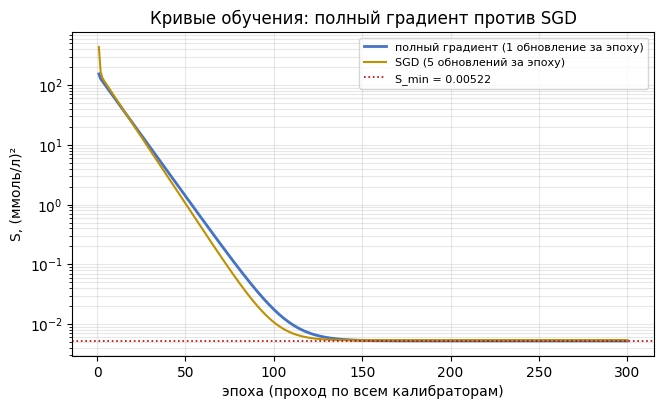

In [41]:
# 4.11* — SGD: обновление после каждого калибратора

def full_gd_epochs(w, b, eta=0.1, epochs=300):
    hist = []
    for _ in range(epochs):
        dw, db = dS_dw(w, b), dS_db(w, b)       # один шаг по всем пяти точкам
        w, b = w - eta * dw, b - eta * db
        hist.append(S(w, b))
    return w, b, hist

def sgd_epochs(w, b, eta=0.1, epochs=300):
    hist = []
    for _ in range(epochs):
        epoch_cost = 0.0
        for A_i, c_i in zip(A_cal, c_cal):      # порядок внутри эпохи не меняем
            dw = 2 * A_i * (w * A_i + b - c_i)  # градиент по одной точке
            db = 2 * (w * A_i + b - c_i)
            w = w - eta * dw                    # шаг сразу после каждого раствора
            b = b - eta * db
            epoch_cost += S(w, b)
        hist.append(epoch_cost / len(A_cal))    # усредняем S внутри эпохи
    return w, b, hist

EPOCHS = 300
w_gd2, b_gd2, h_gd = full_gd_epochs(0.0, 0.0, epochs=EPOCHS)
w_sgd, b_sgd, h_sgd = sgd_epochs(0.0, 0.0, epochs=EPOCHS)
S_min = S(w_mnk, b_mnk)

def first_below(hist, level):
    return next((i + 1 for i, s in enumerate(hist) if s < level), None)

print(f"полный градиент: w = {w_gd2:.6f}, b = {b_gd2:.6f}, S = {h_gd[-1]:.6f}")
print(f"SGD:             w = {w_sgd:.6f}, b = {b_sgd:.6f}, S = {h_sgd[-1]:.6f}")
print(f"S_min по МНК:    w = {w_mnk:.6f}, b = {b_mnk:.6f}, S_min = {S_min:.6f}")
print(f"эпох до S < 0.01: полный градиент — {first_below(h_gd, 0.01)}, "
      f"SGD — {first_below(h_sgd, 0.01)}")
print(f"промах SGD от МНК: |dw| = {abs(w_sgd - w_mnk):.4f}, |db| = {abs(b_sgd - b_mnk):.4f}")
print(f"промах полного градиента от МНК: |dw| = {abs(w_gd2 - w_mnk):.4f}, |db| = {abs(b_gd2 - b_mnk):.4f}")


fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.semilogy(range(1, EPOCHS + 1), h_gd, color='#4472c4', lw=2,
            label='полный градиент (1 обновление за эпоху)')
ax.semilogy(range(1, EPOCHS + 1), h_sgd, color='#bf9000', lw=1.5,
            label='SGD (5 обновлений за эпоху)')
ax.axhline(S_min, color='#c00000', ls=':', lw=1.2, label=f'S_min = {S_min:.5f}')
ax.set_xlabel('эпоха (проход по всем калибраторам)')
ax.set_ylabel('S, (ммоль/л)²')
ax.set_title('Кривые обучения: полный градиент против SGD')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8)
plt.show()


**Вывод:** Стохастический градиентный спуск делает 5 обновлений параметров за одну эпоху (по одному на каждый калибратор), тогда как полный градиент только одно. Поэтому на начальном этапе SGD снижает ошибку быстрее.  При этом SGD задействие немногим меньше итераций, чем полный градиент (102 против 111), но имеет меньшую точность (при сравнении результатов с результатами МНК).

### 4.12*. Физическая прямая и овраг (необязательно, для сильного интереса)

В основном решении ты обучала **рабочий** нейрон $\hat{c} = wA + b$ — ошибка минимизируется в ммоль/л. А теперь обучь **физическую** прямую $A = k\,c + A_0$ по тем же пяти точкам (как в июле): теперь минимизируется ошибка в единицах оптической плотности.

Затем пересчитай её параметры в рабочие: $w' = 1/k$, $b' = -A_0/k$ — и сравни с прямо обученными из 4.6. Совпали до последнего знака? Нет — и это не ошибка округления: два способа минимизируют **разные** величины, поэтому и ответы чуть разные. Какую ошибку важнее минимизировать для пациента — вопрос, который решают реальные калибровочные лаборатории; подумай и запиши своё мнение.

И второе: построй линии уровня физической $S(k, A_0)$. Увидишь вытянутый овраг — знакомую сентябрьскую картинку. Причина в масштабах: концентрации — числа порядка десятков, плотности — долей единицы, и параметры при таких разных масштабах делают чашу длинной и узкой. Из-за оврага спуск по физической прямой сходится с медленным хвостом — а в рабочем направлении (4.5*) чаша почти круглая и хвоста нет.

In [42]:
# 4.12* — физическая прямая, пересчёт весов, сравнение, линии уровня
A_cal = [0.095, 0.183, 0.364, 0.546, 0.723]
c_cal = [2.5, 5.0, 10.0, 15.0, 20.0]
n = len(c_cal)

sum_A = sum(A_cal)
sum_c = sum(c_cal)
sum_c2 = sum(c ** 2 for c in c_cal)
sum_Ac = sum(A_cal[i] * c_cal[i] for i in range(n))
print(f"sum_A = {sum_A} | sum_c = {sum_c} | sum_c2 = {sum_c2} | sum_Ac = {sum_Ac}")

# нормальные уравнения для A = k*c + A0 (ошибка теперь в единицах A)
D = n * sum_c2 - sum_c ** 2
D_k = n * sum_Ac - sum_c * sum_A
D_A0 = sum_c2 * sum_A - sum_c * sum_Ac

k_phys = D_k / D
A0_phys = D_A0 / D
print(f"Физические параметры: k = {k_phys:.6f}, A0 = {A0_phys:.6f}")

sum_A = 1.911 | sum_c = 52.5 | sum_c2 = 756.25 | sum_Ac = 27.4425
Физические параметры: k = 0.035985, A0 = 0.004354


Физический спуск: k = 0.035985, A0 = 0.004354, S_min = 6.756e-06
падение S в 100 раз: физическая — 679 итераций, рабочая — 32
до 5% выше минимума:  физическая — 1035 итераций, рабочая — 141


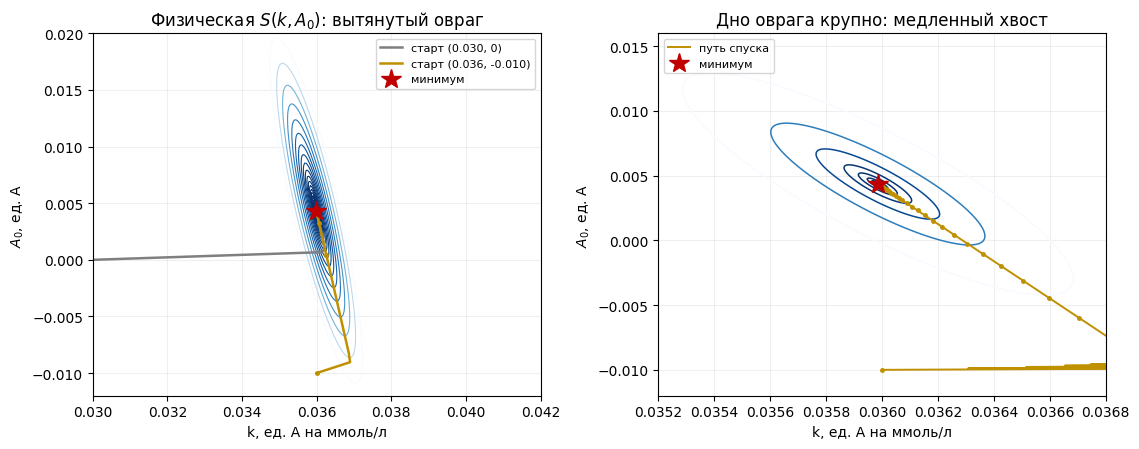

In [43]:
# --- спуск по физической S(k, A0) и линии уровня ---
def S_phys(k, A0):
    return sum((A - (k * c + A0)) ** 2 for A, c in zip(A_cal, c_cal))

def dS_dk(k, A0):
    return -2 * sum(c * (A - k * c - A0) for A, c in zip(A_cal, c_cal))

def dS_dA0(k, A0):
    return -2 * sum(A - k * c - A0 for A, c in zip(A_cal, c_cal))

def S_phys_grid(K, A0g):
    A = np.array(A_cal)
    C = np.array(c_cal)
    return ((A - (K[..., None] * C + A0g[..., None])) ** 2).sum(axis=-1)

def descent_phys(k0, a0, eta=0.0012, iters=20000):
    pts = [(k0, a0)]
    k, a0 = k0, a0
    for _ in range(iters):
        gk, ga = dS_dk(k, a0), dS_dA0(k, a0)   # обе до обновления
        k, a0 = k - eta * gk, a0 - eta * ga
        pts.append((k, a0))
    return np.array(pts)

path_far = descent_phys(0.030, 0.0)        # старт далеко, входит в овраг
path_tail = descent_phys(0.036, -0.010)    # старт прямо в овраге — виден хвост
Smin_p = S_phys(k_phys, A0_phys)

# для сравнения — рабочий спуск из 4.5
w, b = 0.0, 0.0
h_w = [S(w, b)]
for _ in range(2000):
    dw, db = dS_dw(w, b), dS_db(w, b)
    w, b = w - 0.1 * dw, b - 0.1 * db
    h_w.append(S(w, b))
Smin_w = S(w_mnk, b_mnk)

h_tail = [S_phys(k, a0) for k, a0 in path_tail]
it_p_100 = next(i for i, s in enumerate(h_tail) if s <= h_tail[0] / 100)
it_w_100 = next(i for i, s in enumerate(h_w) if s <= h_w[0] / 100)
it_p_5 = next(i for i, s in enumerate(h_tail) if s <= 1.05 * Smin_p)
it_w_5 = next(i for i, s in enumerate(h_w) if s <= 1.05 * Smin_w)

print(f"Физический спуск: k = {path_tail[-1, 0]:.6f}, A0 = {path_tail[-1, 1]:.6f}, "
      f"S_min = {Smin_p:.3e}")
print(f"падение S в 100 раз: физическая — {it_p_100} итераций, рабочая — {it_w_100}")
print(f"до 5% выше минимума:  физическая — {it_p_5} итераций, рабочая — {it_w_5}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# слева — овраг целиком и два пути: издалека и вдоль оврага
K, A0g = np.meshgrid(np.linspace(0.030, 0.042, 320), np.linspace(-0.012, 0.020, 320))
lev = Smin_p + np.logspace(-7, -3.5, 26)
ax1.contour(K, A0g, S_phys_grid(K, A0g), levels=lev, cmap='Blues_r', linewidths=0.8)
ax1.plot(path_far[::20, 0], path_far[::20, 1], color='#7f7f7f', lw=1.8,
         label='старт (0.030, 0)')
ax1.plot(path_tail[::20, 0], path_tail[::20, 1], color='#bf9000', lw=1.8,
         label='старт (0.036, -0.010)')
ax1.plot(path_tail[::400, 0], path_tail[::400, 1], 'o', color='#bf9000', ms=2.5)
ax1.plot(k_phys, A0_phys, '*', color='#c00000', ms=15, label='минимум')
ax1.set_xlabel('k, ед. A на ммоль/л')
ax1.set_ylabel('$A_0$, ед. A')
ax1.set_title('Физическая $S(k, A_0)$: вытянутый овраг')
ax1.set_xlim(0.030, 0.042)
ax1.set_ylim(-0.012, 0.020)
ax1.grid(alpha=0.2)
ax1.legend(fontsize=8, loc='upper right')

# справа — крупно: как спуск ползёт по дну оврага
K2, A02 = np.meshgrid(np.linspace(0.0352, 0.0368, 320), np.linspace(-0.012, 0.016, 320))
lev2 = Smin_p + np.array([1e-7, 3e-7, 1e-6, 3e-6, 1e-5, 3e-5, 1e-4])
ax2.contour(K2, A02, S_phys_grid(K2, A02), levels=lev2, cmap='Blues_r', linewidths=1.1)
ax2.plot(path_tail[:, 0], path_tail[:, 1], color='#bf9000', lw=1.4, label='путь спуска')
ax2.plot(path_tail[::50, 0], path_tail[::50, 1], 'o', color='#bf9000', ms=2.5)
ax2.plot(k_phys, A0_phys, '*', color='#c00000', ms=15, label='минимум')
ax2.set_xlabel('k, ед. A на ммоль/л')
ax2.set_ylabel('$A_0$, ед. A')
ax2.set_title('Дно оврага крупно: медленный хвост')
ax2.set_xlim(0.0352, 0.0368)
ax2.set_ylim(-0.012, 0.016)
ax2.grid(alpha=0.2)
ax2.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.show()


In [44]:
w_prime = 1 / k_phys
b_prime = -A0_phys / k_phys

print(f"Пересчитанные рабочие параметры: w' = {w_prime:.5f}, b' = {b_prime:.5f}")

# Сравниваем с результатами из 4.6
print(f"Параметры из задачи 4.6: w = {w_mnk:.5f}, b = {b_mnk:.5f}")
print(f"Разница по w: {abs(w_prime - w_mnk):.6f}")
print(f"Разница по b: {abs(b_prime - b_mnk):.6f}")

Пересчитанные рабочие параметры: w' = 27.78907, b' = -0.12098
Параметры из задачи 4.6: w = 27.78837, b = -0.12071
Разница по w: 0.000707
Разница по b: 0.000270


**Вывод:** Нет, результаты не совпали до последнего знака. Для пациента критически важно минимизировать ошибку именно по концентрации, так как именно от этого значения зависит постановка диагноза и назначение лечения. Оптическая плотность в данном случае выступает вспомогательным параметром, необходимым для расчета концентрации. Поэтому минимизация ошибки концентрации вещества имеет большее клиническое значение, чем минимизация ошибки оптической плотности.

## Блок 5. Словарь: как это называется в нейросетях

Всё, что ты сделала, в терминах нейросетей называется так:

| В задаче | В нейросетях |
|---|---|
| оптическая плотность $A$ на входе | вход, признак (input, feature) |
| $w$ | вес (weight) |
| $b$ | смещение (bias) |
| $\hat{c} = wA + b$ | нейрон: вход × вес + смещение (активация пока тождественная) |
| $S(w, b)$ | функция потерь (loss function) |
| $\partial S/\partial w$, $\partial S/\partial b$ | градиент |
| $\eta$ | скорость обучения (learning rate) |
| один проход по всем калибраторам | эпоха (epoch) |
| пять калибраторов | обучающая выборка |
| контрольный материал | тестовая выборка |
| прямой проход для пациентской пробы | инференс (inference) |
| $A = kc + b$ — физика прямой (закон Бера) | априорное знание о задаче: подсказывает, какой функцией описывать данные |
| формула МНК | аналитическое решение — существует, пока модель линейна и потери квадратичные; у нейросети его нет, остаётся спуск |
| калибровка раз в смену, пробы весь день | обучение — редко и один раз; инференс — постоянно |

И мостик в апрель. В классификаторе цветов у тебя уже был один нейрон: три входа (R, G, B), три веса, bias и **сигмоида** на выходе, превращающая число в вероятность. Тогда `learning_rate = 10` ломал обучение, а `0.0001` замирал его. Теперь ты знаешь, что это было: $\eta$ — шаг градиентного спуска, и у него есть границы устойчивости. Разница между той задачей и сегодняшней ровно одна: сигмоида и вероятность вместо чистого числа. **Регрессия и классификация — два лица одного и того же нейрона.**

## Блок 6. Границы примера — и куда дальше

Чего этот пример честно **не показывает** — чтобы следующая ступень не выглядела магией:

- **Один нейрон не гнётся.** Закон Бера начинает отклоняться при больших концентрациях — об этом прямо сказано в статье по ссылке из Блока 1. Прямая перестаёт описывать данные, а из любого числа прямых по отдельности кривую не сложишь. Лечится это нелинейностью и **слоями** — это следующий шаг лестницы.
- **Здесь нет локальных минимумов.** $S$ квадратична: чаша одна, спуск обязан дойти до дна. У многослойных сетей ландшафт потерь многоэкстремальный — «капризность» обучения сетей начинается именно там.
- **Нечему распространяться назад.** Цепочка производных от выхода к каждому весу (обратное распространение, backpropagation) появится вместе со вторым слоем. Производные ты здесь взяла руками — и по сути это ровно та же операция.
- **Нейрон всегда ответит.** Формула безотказна: подставь любую $A$ — получишь число, даже там, где верить ему нельзя (проба 2 из 4.10). Границы применимости модели не пишутся в самой модели — их держит человек. Это останется правдой и для больших сетей.
- **Пять точек — два параметра.** Переобучиться на таком материале негде; что такое переобучение, станет видно на данных побольше.

**Куда дальше (задел).** В медицине есть и обратный пример — калибровка компьютерного томографа: перевод единиц HU в плотность ткани для расчёта дозы облучения. Там одной прямой не хватает **даже в рабочем диапазоне**: лёгкое, мягкие ткани и кость живут на разных прямых. Как из нескольких прямых с изломами собрать одну функцию — и почему «излом» это в точности функция ReLU из нейросетей — тема следующего задачника.

**Задача закрыта, когда без ассистента ты можешь:**

1. построить по точкам прямую «концентрация от плотности» и назвать $w$ и $b$ словами;
2. выписать $S(w, b)$ и её частные производные;
3. найти минимум спуском и формулой — и доказать их совпадение;
4. объяснить, что такое холостая проба и при чём здесь точка нуля нейрона;
5. прогнать пробу через нейрон прямым проходом — и сказать, когда ответу верить нельзя;
6. своими словами, в двух предложениях: почему эта прямая — это один нейрон.

---

### Финальная ячейка. Вывод по задаче

Три–пять предложений своими словами: что делает калибровка; что оказалось самым неожиданным; что осталось непонятным. Это не формальность — по этой ячейке видно, что стало твоим, а что прошло мимо.

**Итог:** Калибровка необходима для перевода данных об оптической плотности каждого образца в клинически значимое значение концентрации глюкозы. В ее хоже подбираются такие параметры w и b при которых ошибка калибровки будет минимальна.  